# Issue #319 — Probability Top-2 N7 stable center

Executed decision notebook; paths are repository-relative.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd().parents[2]
OUT=ROOT/'results/top2_n7_stable'

In [2]:
decision=json.loads((OUT/'decision.json').read_text())
performance=pd.read_csv(OUT/'matched_performance.csv')
decision

{'bootstrap_lift_vs_random': {'10h': {'2023': {'block_size': 5,
    'bootstrap_median': 110.94123485719436,
    'ci95_high': 202.78159552271492,
    'ci95_low': 34.93475828630485,
    'draws': 2000,
    'mean_lift_per_issue': 114.18327784498749,
    'n_issues': 43},
   '2024': {'block_size': 5,
    'bootstrap_median': 316.1245530371882,
    'ci95_high': 504.30474868698263,
    'ci95_low': 162.16565138903158,
    'draws': 2000,
    'mean_lift_per_issue': 317.5051190045787,
    'n_issues': 58},
   'combined': {'block_size': 5,
    'bootstrap_median': 227.39459502301366,
    'ci95_high': 354.4804756947828,
    'ci95_low': 125.12851792549864,
    'draws': 2000,
    'mean_lift_per_issue': 230.94235494653492,
    'n_issues': 101}},
  '1h': {'2023': {'block_size': 5,
    'bootstrap_median': 231.82250504370455,
    'ci95_high': 424.98468208700575,
    'ci95_low': 74.4750640716254,
    'draws': 2000,
    'mean_lift_per_issue': 234.66532587735134,
    'n_issues': 42},
   '2024': {'block_size': 5

In [3]:
performance[(performance.horizon=='10h') & (performance.seed.isin([-1,-2]))][['issue_year','arm','active_issues','ending_capital','capital_return','turnover_roi','bundle_hit_rate']]

,issue_year,arm,active_issues,ending_capital,capital_return,turnover_roi,bundle_hit_rate
0,2023,P_TOP2_NO_GATE,43.0,93901.880947,-0.060981,-0.553972,0.186047
32,2024,P_TOP2_NO_GATE,58.0,103567.296902,0.035673,0.240254,0.344828
192,2023,RANDOM_MATCH_P_TOP2_SEED_MEDIAN,46.0,98010.039359,-0.019900,-0.165389,0.125000
193,2024,RANDOM_MATCH_P_TOP2_SEED_MEDIAN,63.0,97688.830139,-0.023112,-0.141063,0.129032


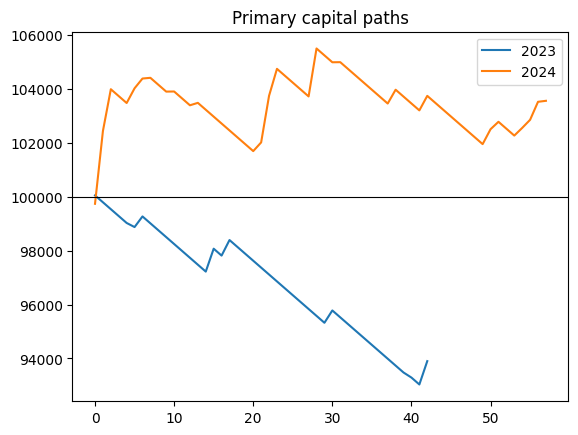

In [4]:
paths=pd.read_csv(OUT/'capital_paths.csv')
for key,g in paths[(paths.horizon=='10h') & (paths.arm=='P_TOP2_NO_GATE')].groupby('issue_year'):
    plt.plot(range(len(g)),g.capital_after,label=str(key))
plt.axhline(100000,color='black',lw=.8); plt.legend(); plt.title('Primary capital paths'); plt.show()